In [ ]:
# Empty for "ruff" extension

# Feature model time benchmark

This notebook focuses on the time required to compute fingerprints by different feature_models.

Todo:

- Test feature model time to fingerprint with different dataset sizes: 100 rows, qqp, something larger?
- Estimate how time grows with data, comparing them with a line graph
- Maybe measure memory used?


In [30]:
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

sys.path.append(str(Path.cwd().parent))

from src.fingerprint import ShingleParams, create_fingerprints
from src.spark_utils import get_spark

%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [26]:
from src.datasets import read_llm_paraphrases

spark = get_spark()

# MODELS = ["embeddings", "shingles (words)", "shingles (chars)", "bag_of_words", "tf-idf"]
MODELS = ["tf-idf"]
SHINGLE_WORDS_CONFIG = ShingleParams(shingle_size=3, over_words=True)
SHINGLE_CHARS_CONFIG = ShingleParams(shingle_size=3, over_words=False)
FINGERPRINT_SIZE = 64
# SAMPLE_SIZES = [1000, 10000, 50000, 100000, 200000, 249998]
SAMPLE_SIZES = [1000, 10000, 50000, 100000, 200000]


COL_IN = "data1"
COL_OUT = "fingerprint1"
df = read_llm_paraphrases()

"""
COL_IN = "data"
COL_OUT = "fingerprint"
df = read_c5()
"""

26/10/09 12:26:03 WARN SparkSession: Using an existing Spark session; only runtime SQL configurations will take effect.
26/10/09 12:26:03 WARN SparkSession: Using an existing Spark session; only runtime SQL configurations will take effect.


'\nCOL_IN = "data"\nCOL_OUT = "fingerprint"\ndf = read_c5()\n'

In [27]:
from src.config import SPARK_SHUFFLE_PARTITIONS


def benchmark(models: list[str], samples: list[int]) -> list[dict]:
    times = []

    for sample_size in samples:
        if sample_size != -1:
            # For some reason, calling limit() on a PySpark DataFrame
            # causes the collapse of the DataFrame partitioning to just one executor.
            # Therefore, it's necessary to repartition the DataFrame to all workers.
            # There's no mention of this in the official docs, afaik.
            df_sample = df.limit(sample_size).repartition(
                numPartitions=int(SPARK_SHUFFLE_PARTITIONS)
            )
        else:
            df_sample = df

        df_sample.cache()
        df_size = df_sample.count()

        for model in models:
            if model == "shingles (words)":
                model_arg = "shingles"
                config = SHINGLE_WORDS_CONFIG
            elif model == "shingles (chars)":
                model_arg = "shingles"
                config = SHINGLE_CHARS_CONFIG
            else:
                model_arg = model
                config = None

            start_time = time.perf_counter()

            df_temp = create_fingerprints(
                df=df_sample,
                model=model_arg,
                input_col=COL_IN,
                output_col=COL_OUT,
                fingerprint_size=FINGERPRINT_SIZE,
                other=config,
            )

            df_temp.write.format("noop").mode("overwrite").save()

            finish_time = time.perf_counter()

            times.append(
                {
                    "model": model,
                    "time": (finish_time - start_time) * 1000,
                    "fingerprint_size": FINGERPRINT_SIZE,
                    "sample_size": df_size,
                }
            )

        df_sample.unpersist()

    return times

In [28]:
df.persist()
times = benchmark(MODELS, SAMPLE_SIZES)
df.unpersist()

26/10/09 12:26:08 WARN CacheManager: Asked to cache already cached data.
26/10/09 12:26:08 WARN SparkSession: Using an existing Spark session; only runtime SQL configurations will take effect.
26/10/09 12:26:13 WARN SparkSession: Using an existing Spark session; only runtime SQL configurations will take effect.
26/10/09 12:26:16 WARN SparkSession: Using an existing Spark session; only runtime SQL configurations will take effect.
26/10/09 12:26:20 WARN SparkSession: Using an existing Spark session; only runtime SQL configurations will take effect.
26/10/09 12:26:25 WARN SparkSession: Using an existing Spark session; only runtime SQL configurations will take effect.


DataFrame[ID: int, data1: string, data2: string, is_near_duplicate: boolean]

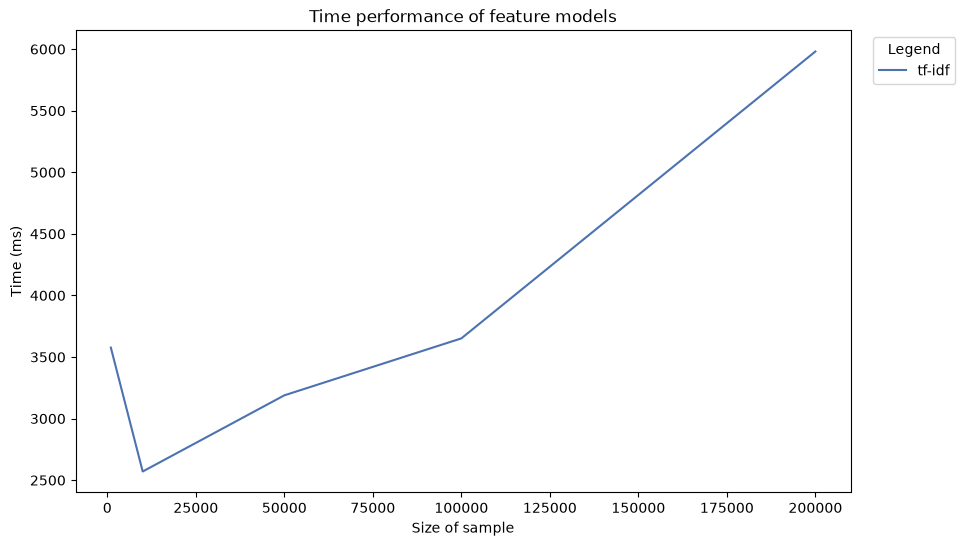

26/10/09 13:04:32 WARN HeartbeatReceiver: Removing executor driver with no recent heartbeats: 308553 ms exceeds timeout 120000 ms
26/10/09 13:04:32 WARN SparkContext: Killing executors is not supported by current scheduler.
26/10/09 13:04:33 ERROR Inbox: Ignoring error
org.apache.spark.SparkException: Exception thrown in awaitResult: 
	at org.apache.spark.util.SparkThreadUtils$.awaitResult(SparkThreadUtils.scala:53)
	at org.apache.spark.util.ThreadUtils$.awaitResult(ThreadUtils.scala:359)
	at org.apache.spark.rpc.RpcTimeout.awaitResult(RpcTimeout.scala:75)
	at org.apache.spark.rpc.RpcEnv.setupEndpointRefByURI(RpcEnv.scala:102)
	at org.apache.spark.rpc.RpcEnv.setupEndpointRef(RpcEnv.scala:110)
	at org.apache.spark.util.RpcUtils$.makeDriverRef(RpcUtils.scala:36)
	at org.apache.spark.storage.BlockManagerMasterEndpoint.driverEndpoint$lzycompute(BlockManagerMasterEndpoint.scala:132)
	at org.apache.spark.storage.BlockManagerMasterEndpoint.org$apache$spark$storage$BlockManagerMasterEndpoint$$

In [29]:
plot_df = pd.DataFrame(times)
plot_df["time"] = plot_df["time"].round(2)
plot_pivot = plot_df.pivot_table(index="sample_size", columns="model", values="time")
plt.figure(figsize=(10, 6))
plot = sns.lineplot(data=plot_pivot, palette="deep")
# plt.title("Time performance of feature models (without tf-idf)")
plt.title("Time performance of feature models")
plt.xlabel("Size of sample")
plt.ylabel("Time (ms)")
plt.legend(title="Legend", loc="upper left", bbox_to_anchor=(1.02, 1))
plt.show()

In [ ]:
spark.stop()